In [10]:
import numpy as np
import matplotlib.pyplot as plt
import schemdraw
import schemdraw.elements as elm
from scipy import signal
from IPython.display import Audio, display

%config InlineBackend.figure_format = 'svg'
FS = 44100


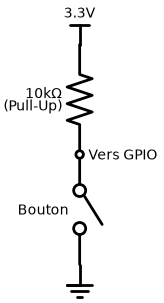

In [11]:
with schemdraw.Drawing() as d:
    d.config(unit=2.2, fontsize=10)
    d += elm.Vdd().label("3.3V")
    d += elm.Resistor().down().label("10kΩ\n(Pull-Up)")
    d.push()
    d += elm.Dot(open=True).label("Vers GPIO", loc="right")
    d.pop()
    d += elm.Switch().down().label("Bouton")
    d += elm.Ground()


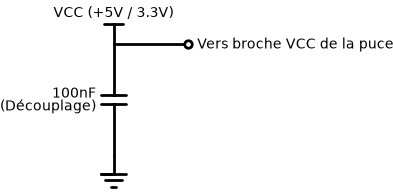

In [12]:
with schemdraw.Drawing() as d:
    d.config(unit=2.2, fontsize=10)
    d += elm.Vdd().label("VCC (+5V / 3.3V)")
    d.push()
    d += elm.Line().right(1.5)
    d += elm.Dot(open=True).label("Vers broche VCC de la puce", loc="right")
    d.pop()
    d += elm.Capacitor().down().label("100nF\n(Découplage)")
    d += elm.Ground()


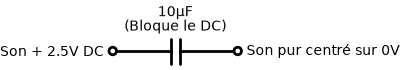

In [13]:
with schemdraw.Drawing() as d:
    d.config(unit=2.5, fontsize=10)
    d += elm.Dot(open=True).label("Son + 2.5V DC", loc="left")
    d += elm.Capacitor().right().label("10µF\n(Bloque le DC)")
    d += elm.Dot(open=True).label("Son pur centré sur 0V", loc="right")


Si R1=10000Ω et R2=10000Ω -> V_out = 50% de V_in


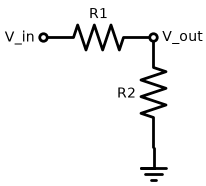

In [14]:
R1, R2 = 10000, 10000  # Divise la tension par 2
print(f"Si R1={R1}Ω et R2={R2}Ω -> V_out = {R2/(R1+R2)*100:.0f}% de V_in")

with schemdraw.Drawing() as d:
    d.config(unit=2.2, fontsize=10)
    d += elm.Dot(open=True).label("V_in", loc="left")
    d += elm.Resistor().right().label("R1")
    d.push()
    d += elm.Dot(open=True).label("V_out", loc="right")
    d.pop()
    d += elm.Resistor().down().label("R2")
    d += elm.Ground()


Coupure des aigus au-dessus de : 1592 Hz


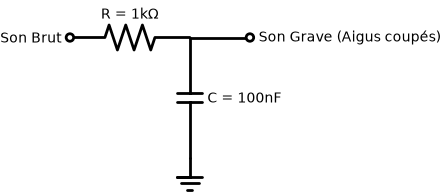

In [15]:
R, C = 1000.0, 100e-9
print(f"Coupure des aigus au-dessus de : {1 / (2 * np.pi * R * C):.0f} Hz")

with schemdraw.Drawing() as d:
    d.config(unit=2.4, fontsize=10)
    d += elm.Dot(open=True).label("Son Brut", loc="left")
    d += elm.Resistor().right().label("R = 1kΩ")
    d.push()
    d += elm.Capacitor().down().label("C = 100nF", loc="bottom")
    d += elm.Ground()
    d.pop()
    d += elm.Line().right(1.2)
    d += elm.Dot(open=True).label("Son Grave (Aigus coupés)", loc="right")


Coupure des graves en dessous de : 159 Hz


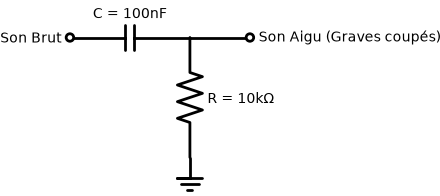

In [16]:
R, C = 10000.0, 100e-9
print(f"Coupure des graves en dessous de : {1 / (2 * np.pi * R * C):.0f} Hz")

with schemdraw.Drawing() as d:
    d.config(unit=2.4, fontsize=10)
    d += elm.Dot(open=True).label("Son Brut", loc="left")
    d += elm.Capacitor().right().label("C = 100nF")
    d.push()
    d += elm.Resistor().down().label("R = 10kΩ", loc="bottom")
    d += elm.Ground()
    d.pop()
    d += elm.Line().right(1.2)
    d += elm.Dot(open=True).label("Son Aigu (Graves coupés)", loc="right")


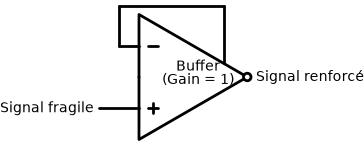

In [17]:
with schemdraw.Drawing() as d:
    d.config(unit=2.2, fontsize=10)
    op = elm.Opamp().label("Buffer\n(Gain = 1)", loc="center")
    d += op
    d += elm.Line().left(0.8).at(op.in2).label("Signal fragile", loc="left")
    d += elm.Line().left(0.4).at(op.in1)
    d += elm.Line().up(0.8)
    d += elm.Line().right(2.1)
    d += elm.Line().down(1.15)
    d += elm.Dot(open=True).at(op.out).label("Signal renforcé", loc="right")


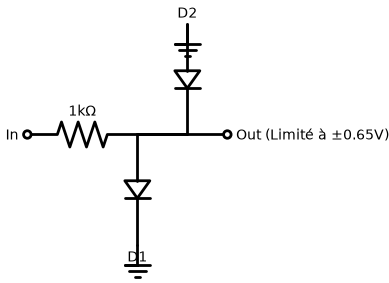

In [18]:
with schemdraw.Drawing() as d:
    d.config(unit=2.2, fontsize=10)
    d += elm.Dot(open=True).label("In", loc="left")
    d += elm.Resistor().right().label("1kΩ")
    d.push()
    d += elm.Diode().down().label("D1", loc="left")
    d += elm.Ground()
    d.pop()
    d.push()
    d += elm.Line().right(1.0)
    d += elm.Diode().up().reverse().label("D2", loc="right")
    d += elm.Ground()
    d.pop()
    d += elm.Line().right(1.8)
    d += elm.Dot(open=True).label("Out (Limité à ±0.65V)", loc="right")

# Écoute rapide de l'effet de cette brique sur un sinus à 110 Hz
t = np.linspace(0, 1.0, FS, endpoint=False)
sin_fort = 2.0 * np.sin(2 * np.pi * 110 * t)
display(Audio(np.clip(sin_fort, -0.65, 0.65) * 0.4, rate=FS))


🔼 Gain = 1 + (22000/10000) = x3.2 (Une entrée de 0.5V devient 1.60V)


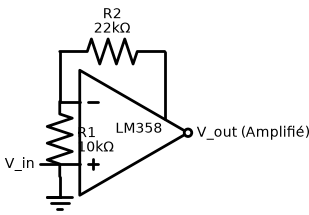

In [19]:
R1 = 10000  # 10 kOhm
R2 = 22000  # 22 kOhm
gain = 1 + (R2 / R1)
print(f"🔼 Gain = 1 + ({R2}/{R1}) = x{gain:.1f} (Une entrée de 0.5V devient {0.5 * gain:.2f}V)")

with schemdraw.Drawing() as d:
    d.config(unit=2.2, fontsize=10)
    op = elm.Opamp().label("LM358", loc="center")
    d += op

    # Entrée sur +
    d += elm.Line().left(0.8).at(op.in2).label("V_in", loc="left")

    # Pont de résistances sur -
    d += elm.Line().left(0.4).at(op.in1)
    d.push()
    d += elm.Resistor().down(1.5).label("R1\n10kΩ", loc="bottom")
    d += elm.Ground()
    d.pop()
    d += elm.Line().up(1.0)
    d += elm.Resistor().right(2.1).label("R2\n22kΩ")
    d += elm.Line().down(1.35)

    d += elm.Dot(open=True).at(op.out).label("V_out (Amplifié)", loc="right")


🔽 Gain = -(33000/10000) = x-3.3 (Une entrée de 0.5V devient -1.65V)


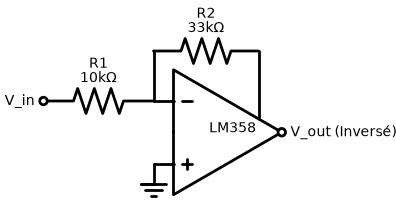

In [20]:
R1 = 10000  # 10 kOhm
R2 = 33000  # 33 kOhm
gain = -(R2 / R1)
print(f"🔽 Gain = -({R2}/{R1}) = x{gain:.1f} (Une entrée de 0.5V devient {0.5 * gain:.2f}V)")

with schemdraw.Drawing() as d:
    d.config(unit=2.2, fontsize=10)
    op = elm.Opamp().label("LM358", loc="center")
    d += op

    # Entrée sur - à travers R1
    d += elm.Line().left(0.4).at(op.in1)
    d.push()
    d += elm.Resistor().left().label("R1\n10kΩ")
    d += elm.Dot(open=True).label("V_in", loc="left")
    d.pop()

    # Boucle de contre-réaction R2
    d += elm.Line().up(1.0)
    d += elm.Resistor().right(2.1).label("R2\n33kΩ")
    d += elm.Line().down(1.35)

    # Broche + à la masse
    d += elm.Line().left(0.4).at(op.in2)
    d += elm.Ground()

    d += elm.Dot(open=True).at(op.out).label("V_out (Inversé)", loc="right")


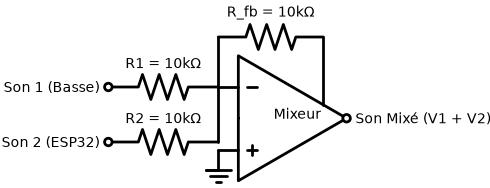

In [21]:
with schemdraw.Drawing() as d:
    d.config(unit=2.2, fontsize=10)
    op = elm.Opamp().label("Mixeur", loc="center")
    d += op

    # Voie 1 (ex: Basse analogique)
    d += elm.Line().left(0.4).at(op.in1)
    d.push()
    d += elm.Resistor().left().label("R1 = 10kΩ")
    d += elm.Dot(open=True).label("Son 1 (Basse)", loc="left")
    d.pop()

    # Voie 2 (ex: Kick + Mélodie ESP32)
    d.push()
    d += elm.Line().down(1.1)
    d += elm.Resistor().left().label("R2 = 10kΩ")
    d += elm.Dot(open=True).label("Son 2 (ESP32)", loc="left")
    d.pop()

    # Résistance de sortie R_fb
    d += elm.Line().up(1.0)
    d += elm.Resistor().right(2.1).label("R_fb = 10kΩ")
    d += elm.Line().down(1.35)

    # Broche + à la masse
    d += elm.Line().left(0.4).at(op.in2)
    d += elm.Ground()

    d += elm.Dot(open=True).at(op.out).label("Son Mixé (V1 + V2)", loc="right")


🎹 Fréquence générée : 70.3 Hz (≈ Do2 / C2) | Rapport cyclique : 51.1%


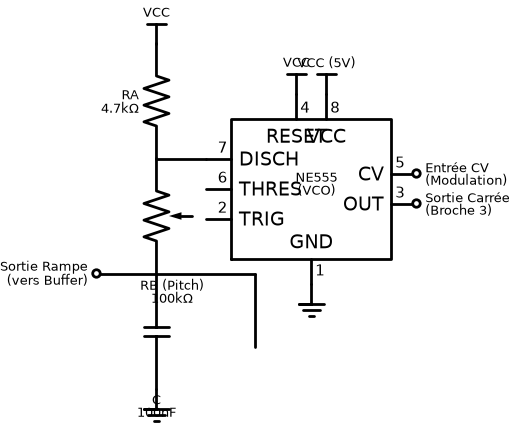

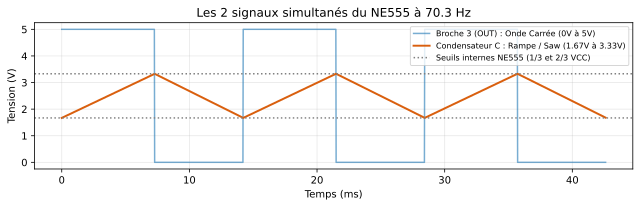

In [23]:
from IPython.display import Audio, display, HTML

# --- 1. CALCUL DES COMPOSANTS POUR UNE NOTE DE BASSE ---
RA = 4700.0     # 4.7 kOhm (résistance fixe de protection)
RB = 100000.0   # Potentiomètre 100 kOhm (ou résistance accordage)
C = 100e-9      # Condensateur 100 nF

freq = 1.44 / ((RA + 2 * RB) * C)
duty = ((RA + RB) / (RA + 2 * RB)) * 100
print(f"🎹 Fréquence générée : {freq:.1f} Hz (≈ Do2 / C2) | Rapport cyclique : {duty:.1f}%")

# --- 2. SCHÉMA DE L'OSCILLATEUR NE555 ---
with schemdraw.Drawing() as d:
    d.config(unit=2.3, fontsize=9)
    ic = elm.Ic(pins=[
        elm.IcPin(name="GND", side="bottom", pin="1"),
        elm.IcPin(name="TRIG", side="left", pin="2"),
        elm.IcPin(name="OUT", side="right", pin="3"),
        elm.IcPin(name="RESET", side="top", pin="4"),
        elm.IcPin(name="CV", side="right", pin="5"),
        elm.IcPin(name="THRES", side="left", pin="6"),
        elm.IcPin(name="DISCH", side="left", pin="7"),
        elm.IcPin(name="VCC", side="top", pin="8"),
    ], edgepadW=1.2, edgepadH=0.8).label("NE555\n(VCO)", loc="center")
    d += ic

    # Alimentation (5V ou 9V)
    d += elm.Vdd().at(ic.VCC).label("VCC (5V)")
    d += elm.Vdd().at(ic.RESET).label("VCC")
    d += elm.Ground().at(ic.GND)

    # Réseau RA, RB et Condensateur C
    d += elm.Line().left(1.0).at(ic.DISCH)
    d.push()
    d += elm.Resistor().up().label("RA\n4.7kΩ")
    d += elm.Vdd().label("VCC")
    d.pop()
    d += elm.Potentiometer().down().label("RB (Pitch)\n100kΩ", loc="left")
    d.push()
    d += elm.Line().right(1.0).to(ic.THRES)
    d += elm.Line().down().to(ic.TRIG)
    d.pop()
    d.push()
    d += elm.Capacitor().down().label("C\n100nF", loc="left")
    d += elm.Ground()
    d.pop()

    # Sortie 1 : Dent de scie (Rampe sur le condensateur -> vers Buffer LM358)
    d += elm.Line().left(1.2)
    d += elm.Dot(open=True).label("Sortie Rampe\n(vers Buffer)", loc="left")

    # Sortie 2 : Onde carrée (Broche 3)
    d += elm.Dot(open=True).at(ic.OUT).label("Sortie Carrée\n(Broche 3)", loc="right")

    # Entrée CV (Broche 5 -> Modulation de fréquence par l'ESP32)
    d += elm.Dot(open=True).at(ic.CV).label("Entrée CV\n(Modulation)", loc="right")

# --- 3. VISUALISATION DES 2 FORMES D'ONDE & ÉCOUTE ---
t = np.linspace(0, 1.2, int(FS * 1.2), endpoint=False)
onde_carree = signal.square(2 * np.pi * freq * t, duty=duty/100.0)
# Charge/décharge exponentielle entre 1/3 VCC (1.67V) et 2/3 VCC (3.33V)
onde_rampe = signal.sawtooth(2 * np.pi * freq * t, width=duty/100.0)

zoom = int((3 / freq) * FS)
plt.figure(figsize=(9, 3))
plt.plot(t[:zoom]*1000, (onde_carree[:zoom] + 1) * 2.5, label="Broche 3 (OUT) : Onde Carrée (0V à 5V)", alpha=0.6)
plt.plot(t[:zoom]*1000, 2.5 + onde_rampe[:zoom] * 0.83, label="Condensateur C : Rampe / Saw (1.67V à 3.33V)", linewidth=2, color="#d95f0e")
plt.axhline(3.33, color="gray", linestyle=":", label="Seuils internes NE555 (1/3 et 2/3 VCC)")
plt.axhline(1.67, color="gray", linestyle=":")
plt.title(f"Les 2 signaux simultanés du NE555 à {freq:.1f} Hz")
plt.xlabel("Temps (ms)")
plt.ylabel("Tension (V)")
plt.legend(loc="upper right", fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(HTML("<b>1. Son de la Broche 3 (Onde Carrée)</b>"))
display(Audio(onde_carree * 0.25, rate=FS))
display(HTML("<b>2. Son du Condensateur C (Onde Rampe / Saw)</b>"))
display(Audio(onde_rampe * 0.35, rate=FS))
